# 03 — Construction du dataset d'entraînement

Justifie les choix de `src/data/build_dataset.py` (documentation : `docs/dataset_entrainement.md`) :

1. Choix du proxy des Champs-Elysées (4267, 4274, 4281)
2. Le dataset construit : couverture, origine des cibles, ruptures
3. Disponibilité des features, en historique et sur la fenêtre à prédire

Prérequis : `python -m src.data.update --history 2010 2025`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import ARCS, CHAMPS_PROXIES, DATASET_PATH, TARGETS, TRAIN_START, TZ
from src.data.build_dataset import arc_series, apply_ratios, build_dataset, fit_ratios, save
from src.data.sources import trafic

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90

## 1. Proxy des Champs-Elysées

L'arc 4264 (Washington → Berri, sens Étoile → Concorde) est muet depuis le 19/11/2025. Candidats sur l'avenue,
**dans le même sens** :

| Arc | Tronçon | Position |
|---|---|---|
| 4267 | Balzac → Washington | juste en amont |
| 4274 | Berri → La Boétie | juste en aval |
| 4281 | Colisée → Rond-Point | deux tronçons en aval |

Méthode de recalage : ratio médian cible / proxy par (heure locale, type de jour : semaine, samedi, dimanche),
appris sur 06/2021 → 12/2024, évalué sur 01/2025 → 19/11/2025 (dernières mesures de 4264).

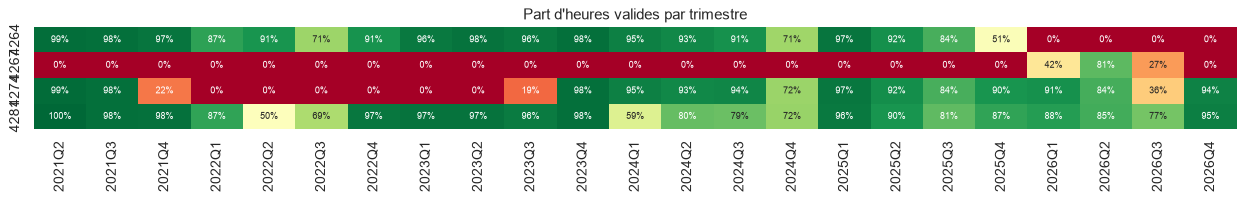

In [2]:
CANDIDATS = ["4267", "4274", "4281"]
hours = pd.date_range(pd.Timestamp(TRAIN_START, tz=TZ).tz_convert("UTC"), pd.Timestamp("2026-11-03", tz="UTC"), freq="h")
raw = trafic.load(["4264", *CANDIDATS])
series = {a: arc_series(raw, a, hours) for a in ["4264", *CANDIDATS]}

valid = pd.DataFrame({a: s["valide"] for a, s in series.items()})
q = valid.groupby(valid.index.tz_localize(None).to_period("Q")).mean().T
fig, ax = plt.subplots(figsize=(14, 2.4))
sns.heatmap(q, cmap="RdYlGn", vmin=0, vmax=1, annot=True, fmt=".0%", cbar=False, ax=ax, annot_kws={"size": 7})
ax.set_title("Part d'heures valides par trimestre"); plt.tight_layout(); plt.show()

**4267 est inutilisable** : aucune heure valide entre 2021 et fin 2025 (donc pas de période commune avec 4264 pour
apprendre un recalage), et muet depuis août 2026 (pas de lags pour la fenêtre à prédire). On compare 4274 et 4281.

In [3]:
target = series["4264"]
train = target.index < pd.Timestamp("2025-01-01", tz="UTC")
test = (target.index >= pd.Timestamp("2025-01-01", tz="UTC")) & (target.index < pd.Timestamp("2025-11-19", tz="UTC"))

rows, recon = [], {}
for col in TARGETS:
    y = target[col].where(target["valide"])
    preds = {}
    for p in ["4274", "4281"]:
        x = series[p][col].where(series[p]["valide"])
        preds[p] = apply_ratios(x, fit_ratios(y.where(train), x))
    preds["moyenne 4274/4281"] = pd.concat([preds["4274"], preds["4281"]], axis=1).mean(axis=1, skipna=False)
    common = pd.concat([y, *preds.values()], axis=1)[test].dropna().index
    for name, pr in preds.items():
        e = pr[common] - y[common]
        rows.append({"cible": col, "proxy": name, "heures test": len(common), "MAE": e.abs().mean(),
                     "RMSE": np.sqrt((e ** 2).mean()), "biais": e.mean(), "corr": y[common].corr(pr[common]),
                     "MAE / moyenne": e.abs().mean() / y[common].mean()})
    recon[col] = (y, preds)
pd.DataFrame(rows).set_index(["cible", "proxy"]).round(3)

heures test     MAE     RMSE   biais   corr  MAE / moyenne
cible           proxy                                                                        
debit_horaire   4274                      6892  46.318   72.682 -13.650  0.967          0.062
                4281                      6892  72.002  113.413  13.453  0.925          0.096
                moyenne 4274/4281         6892  50.985   79.488  -0.099  0.960          0.068
taux_occupation 4274                      6892   5.498    9.077  -0.805  0.571          0.360
                4281                      6892   4.542   10.255   0.897  0.612          0.297
                moyenne 4274/4281         6892   4.134    7.643   0.046  0.684          0.271

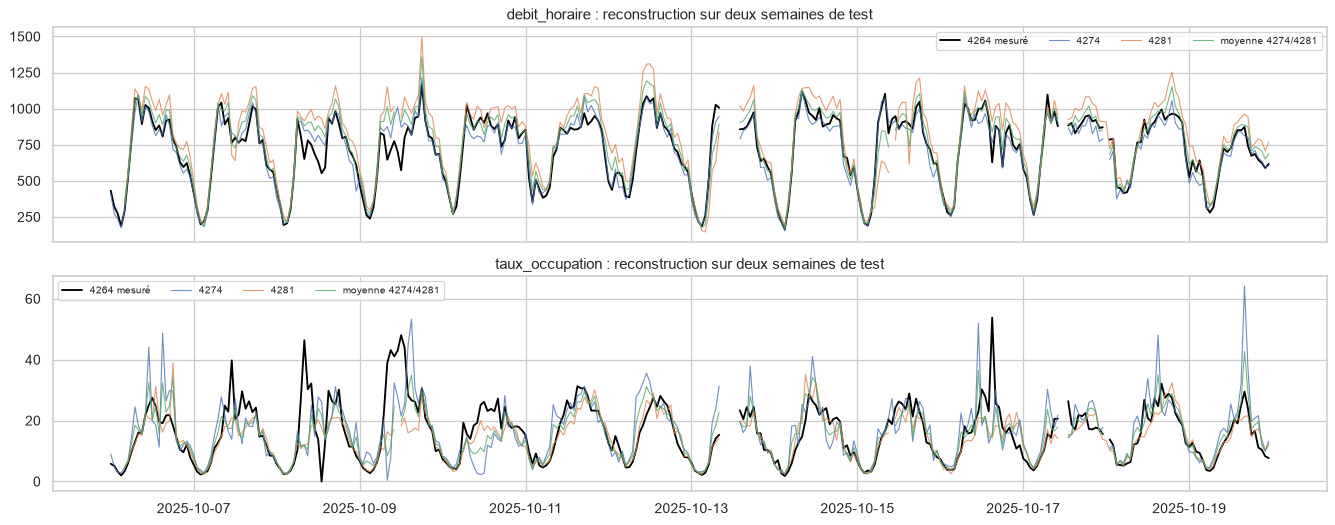

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
sl = slice("2025-10-06", "2025-10-19")
for ax, col in zip(axes, TARGETS):
    y, preds = recon[col]
    ax.plot(y[sl].index, y[sl], color="black", lw=1.5, label="4264 mesuré")
    for name, pr in preds.items():
        ax.plot(pr[sl].index, pr[sl], lw=0.9, alpha=0.8, label=name)
    ax.set_title(f"{col} : reconstruction sur deux semaines de test"); ax.legend(fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

In [5]:
# Stabilité du recalage : ratio médian cible/proxy par trimestre (un ratio qui dérive invaliderait la méthode)
rat = {}
for col in TARGETS:
    y = target[col].where(target["valide"])
    for p in ["4274", "4281"]:
        x = series[p][col].where(series[p]["valide"])
        r = (y / x.where(x > 0)).dropna()
        rat[(col, p)] = r.groupby(r.index.tz_localize(None).to_period("Q")).median()
pd.DataFrame(rat).round(2).T

2021Q2  2021Q3  2021Q4  2022Q1  2022Q2  2022Q3  2022Q4  2023Q1  2023Q2  2023Q3  2023Q4  2024Q1  2024Q2  2024Q3  2024Q4  2025Q1  2025Q2  2025Q3  2025Q4
debit_horaire   4274    0.93    0.99    1.00     NaN     NaN     NaN     NaN     NaN     NaN    1.09    1.14    1.04    1.03    1.06    1.03    1.03    1.02    1.08    1.07
                4281    0.94    1.02    0.99    0.94    1.00    0.95    1.24    1.26    1.20    1.30    1.32    1.23   16.63    2.80    1.17    1.13    1.15    1.19    1.11
taux_occupation 4274    1.60    1.51    1.74     NaN     NaN     NaN     NaN     NaN     NaN    2.23    2.15    1.80    1.73    2.24    2.10    1.96    2.24    1.89    1.85
                4281    1.23    1.54    1.78    1.52    1.96    1.41    3.02    2.53    2.67    3.22    3.16    2.65    1.02    2.06    2.51    2.17    2.15    2.47    2.34

In [6]:
# Faut-il n'apprendre le recalage que sur la période récente ? (4281 change de niveau fin 2022)
res = {}
for calib_start in ["2021-06-21", "2023-07-01", "2024-01-01"]:
    tr = (target.index >= pd.Timestamp(calib_start, tz="UTC")) & train
    for col in TARGETS:
        y = target[col].where(target["valide"])
        preds = {p: apply_ratios(series[p][col].where(series[p]["valide"]),
                                 fit_ratios(y.where(tr), series[p][col].where(series[p]["valide"]))) for p in ["4274", "4281"]}
        preds["moyenne"] = pd.concat(preds.values(), axis=1).mean(axis=1, skipna=False)
        common = pd.concat([y, *preds.values()], axis=1)[test].dropna().index
        for name, pr in preds.items():
            res[(calib_start, col, name)] = (pr[common] - y[common]).abs().mean()
pd.Series(res).unstack([1, 2]).round(2)

debit_horaire                 taux_occupation              
                    4274    4281 moyenne            4274  4281 moyenne
2021-06-21         46.31   72.01   50.99            5.50  4.54    4.13
2023-07-01         46.42  117.18   69.92            5.62  5.70    4.60
2024-01-01         46.33  517.37  262.47            5.55  4.70    4.22

**Décision (D1)**
- **Débit** : 4274 seul (MAE ≈ 46 véh/h, soit ~6 % ; corrélation 0,97) ; 4281 en secours quand 4274 manque.
- **Occupation** : moyenne de 4274 et 4281 recalés (MAE ≈ 4,1 points contre 5,5 pour 4274 seul) : les erreurs des
  deux proxys se compensent en partie. L'occupation reste la cible la moins bien reconstruite (corrélation ~0,7).
- Une heure n'est reconstruite que si **les deux** cibles le sont, pour garder un couple cohérent.
- Le ratio débit 4264/4274 est stable dans le temps (0,93-1,14). Celui de 4281 saute fin 2022 (~0,95 → ~1,25) et
  explose au 2e trimestre 2024 (anomalie de 4281, débits anormalement bas) : 4281 n'est qu'un secours pour le débit.
- Recalage appris sur **toute la période commune depuis 06/2021** : restreindre à 2023+ ou 2024+ dégrade le résultat
  (moins d'heures, et l'anomalie 2024 de 4281 pèse plus lourd).
- L'occupation reconstruite est la principale incertitude de la cible Champs-Elysées après le 19/11/2025.

Configuration : `CHAMPS_PROXIES` dans `src/config.py`.

## 2. Le dataset construit

In [7]:
df, meta = build_dataset()
save(df, meta)
print(f"{len(df):,} lignes x {df.shape[1]} colonnes ; {df['datetime'].min()} -> {df['datetime'].max()} (UTC)")
print("dernière heure observée :", meta["last_observed"])
pd.crosstab(df["arc"], [df["partie"], df["source_cible"]])

141,843 lignes x 48 colonnes ; 2021-06-20 22:00:00+00:00 -> 2026-11-11 22:00:00+00:00 (UTC)
dernière heure observée : 2026-11-02 23:00:00+00:00


partie         a_predire historique              non_predit
source_cible       futur     absent mesure proxy      futur
arc                                                        
Champs-Elysées       120       4259  35253  7554         95
Convention           120      16692  30374     0         95
Saint-Pères          120      11826  35240     0         95

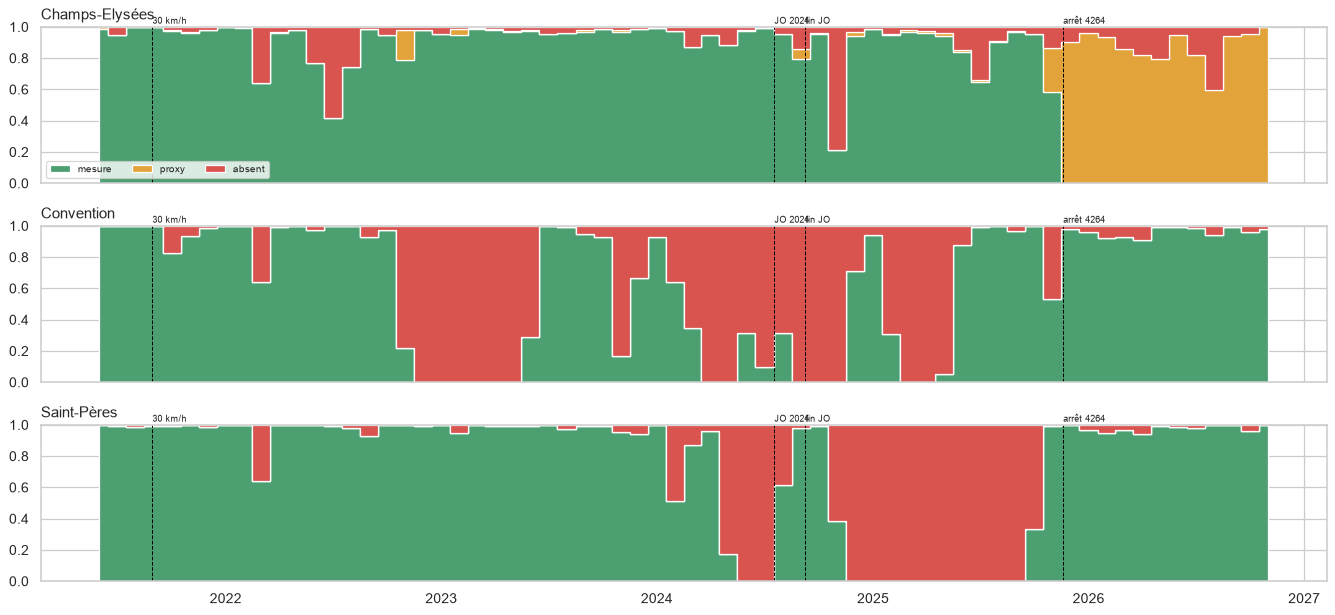

In [8]:
# Origine de la cible par mois et par arc, avec les ruptures connues
src = df[df["partie"] == "historique"].copy()
src["mois"] = src["datetime"].dt.tz_localize(None).dt.to_period("M").dt.to_timestamp()
share = src.groupby(["arc", "mois", "source_cible"]).size().unstack(fill_value=0)
share = share.div(share.sum(axis=1), axis=0)

RUPTURES = {"30 km/h": "2021-08-30", "JO 2024": "2024-07-18", "fin JO": "2024-09-08", "arrêt 4264": "2025-11-19"}
fig, axes = plt.subplots(3, 1, figsize=(15, 7), sharex=True)
colors = {"mesure": "#4c9f70", "proxy": "#e3a33b", "absent": "#d9534f"}
for ax, arc in zip(axes, ARCS):
    s = share.loc[arc].reindex(columns=["mesure", "proxy", "absent"], fill_value=0)
    ax.stackplot(s.index, *[s[c] for c in s.columns], colors=[colors[c] for c in s.columns], labels=s.columns, step="mid")
    for name, d in RUPTURES.items():
        ax.axvline(pd.Timestamp(d), color="black", ls="--", lw=0.8)
        ax.text(pd.Timestamp(d), 1.02, name, fontsize=7, rotation=0)
    ax.set_ylim(0, 1); ax.set_title(arc, loc="left")
axes[0].legend(loc="lower left", fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

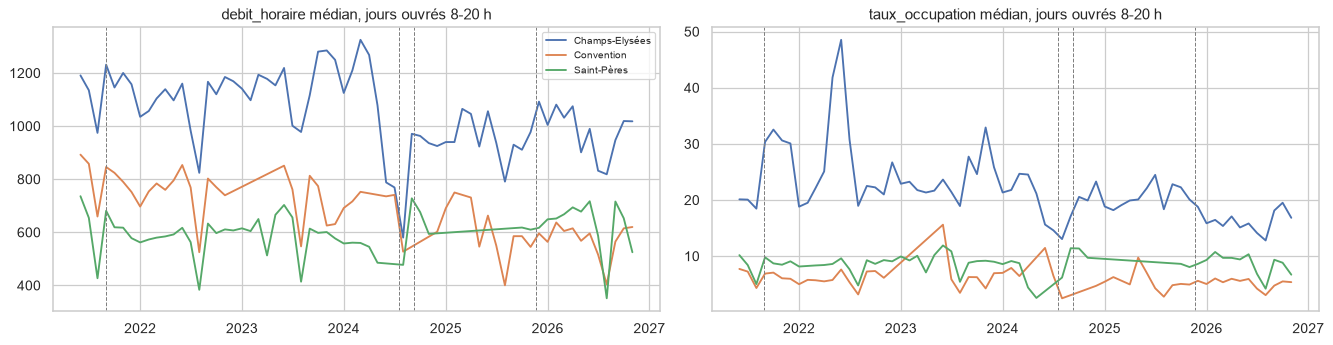

In [9]:
# Niveaux mensuels (jours ouvrés 8-20 h) : les ruptures restantes dans la période retenue
loc = df["datetime"].dt.tz_convert(TZ)
jo = df["is_valid"] & (loc.dt.day_of_week < 5) & loc.dt.hour.between(8, 19)
m = df[jo].groupby(["arc", df.loc[jo, "datetime"].dt.tz_localize(None).dt.to_period("M")])[TARGETS].median()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for j, col in enumerate(TARGETS):
    for arc in ARCS:
        s = m.loc[arc, col]
        axes[j].plot(s.index.to_timestamp(), s, label=arc)
    for name, d in RUPTURES.items():
        axes[j].axvline(pd.Timestamp(d), color="grey", ls="--", lw=0.8)
    axes[j].set_title(f"{col} médian, jours ouvrés 8-20 h")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Disponibilité des features

In [10]:
feature_cols = [c for c in df.columns if c not in ["arc", "datetime", *TARGETS, "is_valid", "source_cible", "partie"]]
na = pd.DataFrame({
    "historique (lignes valides)": df.loc[df["is_valid"], feature_cols].isna().mean(),
    "fenêtre à prédire": df.loc[df["partie"] == "a_predire", feature_cols].isna().mean(),
}).round(3)
na[na.sum(axis=1) > 0]

,historique (lignes valides),fenêtre à prédire
debit_horaire_lag168,0.061,0.394
taux_occupation_lag168,0.061,0.394
debit_horaire_lag336,0.082,0.203
taux_occupation_lag336,0.082,0.203
debit_horaire_lag504,0.090,0.017
taux_occupation_lag504,0.090,0.017
debit_horaire_lag_mean,0.016,0.000
taux_occupation_lag_mean,0.016,0.000
debit_horaire_niveau28j,0.025,0.000
taux_occupation_niveau28j,0.025,0.000


- Les `meteo_obs_*` sont vides sur la fenêtre, c'est voulu : elles servent à l'analyse, le modèle utilise `meteo_*`
  (prévisions).
- Les lags S-1 et S-2 sont partiellement vides sur la fenêtre tant que les données s'arrêtent avant le 05/11 au soir :
  au téléchargement du 06/11 ils seront complets (cutoff 05/11 23:00 + 144 h = début de la fenêtre).
- En historique, ~16-23 % des lags manquent à cause des trous de Convention et Saint-Pères : un GBM gère les NaN.

In [11]:
df.loc[df["partie"] == "a_predire"].head(3).T

,47161,47162,47163
datetime,2026-11-06 23:00:00+00:00,2026-11-07 00:00:00+00:00,2026-11-07 01:00:00+00:00
debit_horaire,NaN,NaN,NaN
taux_occupation,NaN,NaN,NaN
is_valid,False,False,False
source_cible,futur,futur,futur
arc,Champs-Elysées,Champs-Elysées,Champs-Elysées
hour,0,1,2
dow,5,5,5
month,11,11,11
is_weekend,True,True,True
